In [1]:
import warnings
warnings.filterwarnings('ignore')
from tensorflow import keras
from keras.layers import Input, Lambda, Dense, Flatten
from keras.models import Model
from keras.applications.vgg16 import VGG16
from keras.applications.vgg16 import preprocess_input
from keras.preprocessing import image
from keras.preprocessing.image import ImageDataGenerator
from keras.models import Sequential
import numpy as np
from glob import glob
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [18]:
%cd /content/drive/MyDrive/Pneumoniadataset/
!unzip /content/drive/MyDrive/chest_xraydataset.zip -d .


Streaming output truncated to the last 5000 lines.
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0442-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0444-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0445-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0446-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0447-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0448-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0449-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0450-0001.jpeg  
  inflating: ./chest_xray dataset/chest_xray/train/NORMAL/IM-0451-0001.jpeg  
  inflating: 

In [20]:
IMAGE_SIZE = [224, 224]

train_path = '/content/drive/MyDrive/chest_xray/train'
valid_path = '/content/drive/MyDrive/chest_xray/val'

In [22]:
vgg = VGG16(input_shape=IMAGE_SIZE + [3], weights='imagenet', include_top=False)

In [23]:
for layer in vgg.layers:
    layer.trainable = False

In [24]:
folders = glob('/content/drive/MyDrive/chest_xray/train/*')
x = Flatten()(vgg.output)

In [25]:
prediction = Dense(len(folders), activation='softmax')(x)
# create a model object
model = Model(inputs=vgg.input, outputs=prediction)
# view the structure of the model
model.summary()

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0   

In [26]:
model.compile(
  loss='categorical_crossentropy',
  optimizer='adam',
  metrics=['accuracy']
)

In [27]:
from keras.preprocessing.image import ImageDataGenerator

In [28]:
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)

test_datagen = ImageDataGenerator(rescale = 1./255)




# Make sure you provide the same target size as initialied for the image size
training_set = train_datagen.flow_from_directory('/content/drive/MyDrive/chest_xray/train',
                                                 target_size = (224, 224),
                                                 batch_size = 10,
                                                 class_mode = 'categorical')




test_set = test_datagen.flow_from_directory('/content/drive/MyDrive/chest_xray/test',
                                            target_size = (224, 224),
                                            batch_size = 10,
                                            class_mode = 'categorical')




Found 5216 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [30]:
r = model.fit_generator(
  training_set,
  validation_data=test_set,
  epochs=1,
  steps_per_epoch=len(training_set),
  validation_steps=len(test_set)
)



522/522 [==============================] - 3770s 7s/step - loss: 0.2097 - accuracy: 0.9314 - val_loss: 0.3060 - val_accuracy: 0.9119


In [31]:
import tensorflow as tf
from keras.models import load_model

model.save('/content/drive/MyDrive/chest_xray/minemodel.h5')

In [32]:
from keras.models import load_model
from keras.preprocessing import image
from keras.applications.vgg16 import preprocess_input
import numpy as np

In [33]:
model=load_model('/content/drive/MyDrive/chest_xray/minemodel.h5')

1/1 [==============================] - 1s 544ms/step


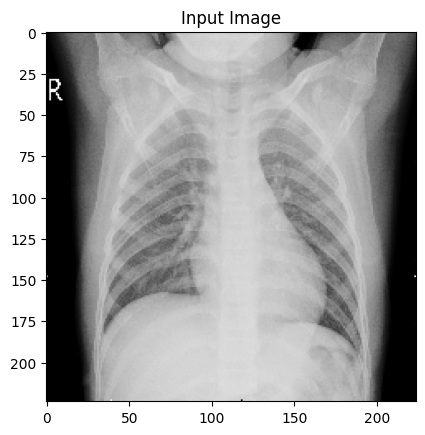

Normal


In [40]:
img=image.load_img('/content/drive/MyDrive/chest_xray/val/NORMAL/NORMAL2-IM-1427-0001.jpeg',target_size=(224,224))
x=image.img_to_array(img)
x=np.expand_dims(x, axis=0)
img_data=preprocess_input(x)
classes=model.predict(img_data)
result=int(classes[0][0])
plt.imshow(img)
plt.title('Input Image')
plt.show()
if result==0:
    print("PNEUMONIA")
else:
    print("Normal")

1/1 [==============================] - 1s 553ms/step


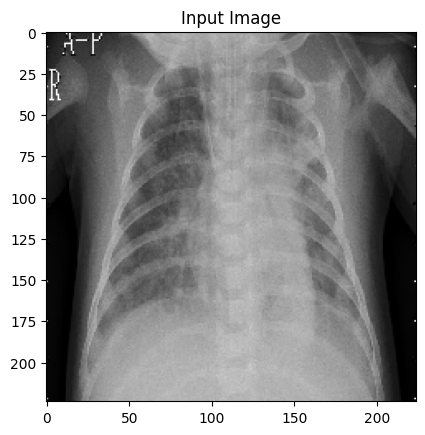

PNEUMONIA


In [41]:
img=image.load_img('/content/drive/MyDrive/chest_xray/val/PNEUMONIA/person1946_bacteria_4874.jpeg',target_size=(224,224))
x=image.img_to_array(img)
x=np.expand_dims(x, axis=0)
img_data=preprocess_input(x)
classes=model.predict(img_data)
result=int(classes[0][0])
plt.imshow(img)
plt.title('Input Image')
plt.show()
if result==0:
    print("PNEUMONIA")
else:
    print("Normal")

63/63 [==============================] - 381s 6s/step


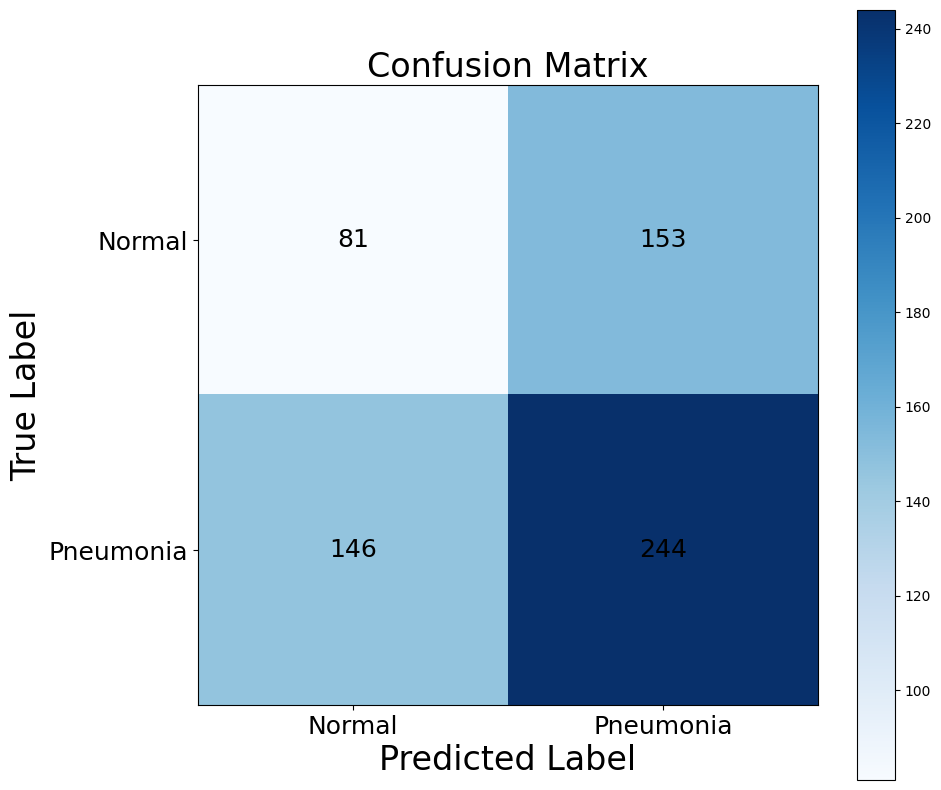

In [42]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Get the true labels and predicted labels
true_labels = test_set.classes
predicted_labels = np.argmax(model.predict(test_set), axis=1)

# Create the confusion matrix
cm = confusion_matrix(true_labels, predicted_labels)

# Define the labels for the axes
labels = ['Normal', 'Pneumonia']

# Plot the confusion matrix
plt.figure(figsize=(10, 10))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix', fontsize=24)
plt.colorbar()
tick_marks = np.arange(len(labels))
plt.xticks(tick_marks, labels, fontsize=18)
plt.yticks(tick_marks, labels, fontsize=18)

# Fill in the cells with the numbers
for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, str(cm[i][j]), ha='center', va='center', fontsize=18)

plt.xlabel('Predicted Label', fontsize=24)
plt.ylabel('True Label', fontsize=24)
plt.show()


In [43]:
from sklearn.metrics import classification_report

# Get the true labels and predicted labels
true_labels = test_set.classes
predicted_labels = np.argmax(model.predict(test_set), axis=1)

# Generate the classification report
report = classification_report(true_labels, predicted_labels)

# Print the classification report
print(report)


63/63 [==============================] - 380s 6s/step
              precision    recall  f1-score   support

           0       0.33      0.32      0.33       234
           1       0.60      0.61      0.61       390

    accuracy                           0.50       624
   macro avg       0.47      0.47      0.47       624
weighted avg       0.50      0.50      0.50       624

